# t-tests

In the chapter on [comparing two means](https://ethanweed.github.io/pythonbook/05.02-ttest.html) in Learning Statistics with Python, you can read about t-tests. Very briefly, if we want to compare the mean of a distribution of data with a specific number (any number), we can use a [one-sample t-test](https://ethanweed.github.io/pythonbook/05.02-ttest.html#the-one-sample-t-test). This test was developed for quality control at a brewery to answer the question of whether the chemical properties of small samples of the barley used to brew beer were, on average, different from the expected values. If we want to compare two _independent_ samples (a treatment group and a control group, a clinical group and a control group, etc.), we can use an [independent samples t-test. I recommend using the Welch version](https://ethanweed.github.io/pythonbook/05.02-ttest.html#the-independent-samples-t-test-welch-test), because it does not assume that the variation is equal in both groups. Very often, this will be the case; for example, clinical samples will often have more variation in their data than the control sample. Finally, if we want to compare the same group but in two different conditions, we can use a [paired-samples t-test](https://ethanweed.github.io/pythonbook/05.02-ttest.html#the-paired-samples-t-test), which is really just the same as a one-sample t-test, where we subtract the value for each participant in one condition from that same participant's value in the other condition to get a difference score, and then compare the mean of the difference scores to zero.

Even more briefly:
1. Compare one sample with specific number: [one-sample t-test](https://ethanweed.github.io/pythonbook/05.02-ttest.html#the-one-sample-t-test)
2. Compare two different groups: [independent samples t-test](https://ethanweed.github.io/pythonbook/05.02-ttest.html#the-independent-samples-t-test-welch-test)
3. Compare one group in two conditions: [paired-samples t-test](https://ethanweed.github.io/pythonbook/05.02-ttest.html#the-paired-samples-t-test)

Follow the links above for examples of how to perform each of these tests in Python, using the ``pingouin`` package. Remember that you will need to ``%pip install pingouin`` when you run your code on UCloud. Also, be aware that you may need to do some re-arranging of the data in ``pandas`` before you can run the t-test in ``pingouin``




In [1]:
%pip install pingouin


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Working with t-tests

Below are 5 sets of data. Each of them have questions which can be addressed using a t-test. For each dataset:

1. Identify the research question
2. Choose the appropriate t-test
3. Do the t-test in Python (see chapter and/or slides for code)
4. Report your results using the APA format, just like in the examples in the book (e.g. With a mean grade of 72.3, the psychology students scored slightly higher than the average grade of 67.5 (𝑡(19)=2.25, 𝑝<.05))
5. Make a figure which illustrates the results

NB: for some of these data sets, you may have to re-arrange the data a little before you can do your analysis! If the data are in long format, where there is a column with a grouping variable, like the example below, an easy way to get data out so they can be entered in a t-test is to make two new variables, like this:

| ID number | Group  | Measure |
| :-------: | :----: | :-----: |
|     1     | A      |   32    |
|     2     | B      |  43.2   |
|     3     | A      |  31.2   |
|     4     | B      |  22.1   |

```python
Group1 = df.loc[df['Group'] == 'A', 'Measure']
Group2 = df.loc[df['Group'] == 'B', 'Measure']
```

Now the t-test can be done with Group1 and Group2.

## Dataset 1: "Moon and Aggression"

Description:

This data set, "Moon & Aggression", provides the number of disruptive behaviors by dementia patients during two different phases of the lunar cycle (Moore et al, 2012, p. 410). Each row corresponds to one participant.

Variables:

Moon: The average number of disruptive behaviors during full moon days.  
Other: The average number of disruptive behaviors during other days.  

Assignment:
Examine the adequacy of the null hypothesis which states that the average number of disruptive behaviors among patients with dementia does not differ between moon days and other days. Calculate an appropriate test statistic, and make a figure illustrating the comparison. Write a sentence reporting your results in the same way they are reported in the book (APA format): 

> With a mean grade of 72.3, the psychology students scored slightly higher than the average grade of 67.5 (𝑡(19)=2.25, 𝑝<.05)

References:

Moore, D. S., McCabe, G. P., and Craig, B. A. (2012). Introduction to the Practice of Statistics (7th ed.). New York: Freeman.

"These data were collected as part of a larger study of dementia patients conducted by Nancy Edwards and Alan Beck, Purdue University." (Moore et al, 2012, p. N-8). 

In [1]:
# import all the packages I'll need
import pandas as pd
import pingouin as pg
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load the dataset
df_moon = pd.read_csv('https://raw.githubusercontent.com/ethanweed/datasets-for-teaching/main/JASP_data_library/2.%20T-Tests/Moon%20and%20Aggression.csv')
df_moon.head()

,Moon,Other
0,3.33,0.27
1,3.67,0.59
2,2.67,0.32
3,3.33,0.19
4,3.33,1.26


You'll look at visualisations in more detail with Ethan, so if you're really confused on how to make one, then for now just study the visualisation code below to get familiar with how it's done. But I do encourage you to try to make your own if you're up for it.

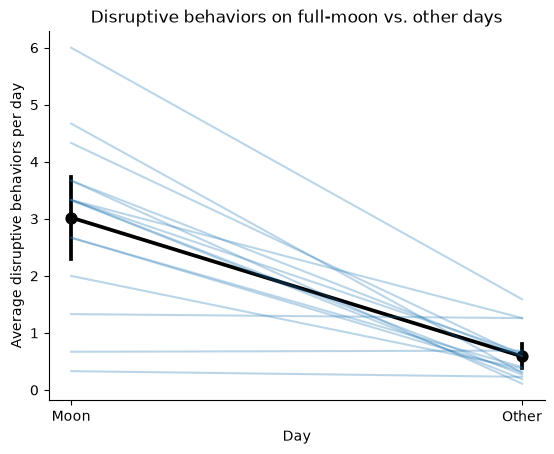

In [8]:
# visualisations
# reshape to long format for plotting, because we want to
df_moon_long = df_moon.reset_index().melt(id_vars='index', var_name='Day', value_name='Behaviors')

fig, ax = plt.subplots()
sns.pointplot(data=df_moon_long, x='Day', y='Behaviors', errorbar=('ci', 95), color='black', ax=ax)
sns.lineplot(data=df_moon_long, x='Day', y='Behaviors', units='index', estimator=None, alpha=0.3, ax=ax)
ax.set_ylabel('Average disruptive behaviors per day')
ax.set_title('Disruptive behaviors on full-moon vs. other days')
sns.despine()


In [19]:
from pingouin import ttest


pg.ttest(df_moon['Moon'], df_moon['Other'], paired = True)

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,6.451789,14,two-sided,0.000015,"[1.62, 3.24]",2.200516,1.0,1521.058


In [30]:
print(df_moon['Moon'].mean())

3.022


In [31]:
print(df_moon['Other'].mean())

0.5893333333333335


Lise: With a mean grade of 3.022 during full moon days, the dementia patient had less disruptive behaviours during non-full moon days with a mean of 0.589 (t(14)=6.45, p<.05)



## Dataset 2: "Horizontal Eye Movements"

Description:

This data set, "Horizontal Eye Movements", provides the number of recalled words by two groups of participants - during the retention interval, one group was instructed to fixate on a centrally presented dot; the other group was instructed to execute horizontal saccades. Specifically, 

"Participants were presented with a list of neutral study words for a subsequent free recall test. Prior to recall, participants were requested to perform - depending on the experimental condition - either horizontal, vertical, or no eye movements (i.e., looking at a central fixation point). The type of eye movement was thus manipulated between subjects. As the effect of eye movement on episodic memory has been reported to be influenced by handedness, we tested only strong right-handed individuals. The dependent variable of interest was the number of correctly recalled words." (Matzke et al, 2015, p. 3)

This data set contains only data from participants assigned to the horizontal and no eye movements conditions; the vertical eye movement data have been removed. 


Variables:

ParticipantNumber - Participant's identification number.  
Condition - Experimental condition (Fixation = fixed gaze, Horizontal = horizontal eye movements).  
CriticalRecall - The number of Recalled words after the memory retrieval task.   

Assignment:
Examine whether the data are more likely to occur if horizontal eye movements do not help memory retrieval (null hypothesis), or _if they have a positive effect on the memory retrieval (one-sided alternative hypothesis)_. Calculate an appropriate test statistic, and make a figure illustrating the comparison. Write a sentence reporting your results in the same way they are reported in the book (APA format): 

> With a mean grade of 72.3, the psychology students scored slightly higher than the average grade of 67.5 (𝑡(19)=2.25, 𝑝<.05)

Reference:

Matzke, D., Nieuwenhuis, S., van Rijn, H., Slagter, H. A., van der Molen, M. W., and Wagenmakers, E.-J. (2015). The effect of horizontal eye movements on free recall: A preregistered adversarial collaboration. Journal of Experimental Psychology: General, 144, e1–e15.

In [8]:
df_eye = pd.read_csv('https://raw.githubusercontent.com/ethanweed/datasets-for-teaching/main/JASP_data_library/2.%20T-Tests/Eye%20Movements.csv')
df_eye.head()

,ParticipantNumber,Condition,CriticalRecall
0,1,Horizontal,4
1,3,Fixation,14
2,4,Horizontal,12
3,6,Fixation,4
4,7,Horizontal,11


Visualisation script below, but try on your own if you feel up for it

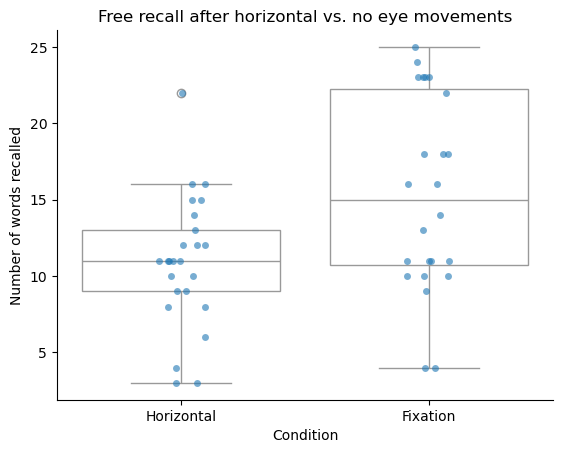

In [12]:
fig, ax = plt.subplots()
sns.boxplot(data=df_eye, x='Condition', y='CriticalRecall', color='white', ax=ax)
sns.stripplot(data=df_eye, x='Condition', y='CriticalRecall', alpha=0.6, ax=ax)
ax.set_ylabel('Number of words recalled')
ax.set_title('Free recall after horizontal vs. no eye movements')
sns.despine()

## Dataset 3: "Laser Blue Jeans"

Description: 

Experiment comparing tensile strength and extension of blue
jeans that were designed using two methods: manually and with laser beams. Designers of blue jeans often want to treat areas of the jeans to give them a faded look by blasting them with quartz sand under high pressure. The areas to be treated with sand need to be marked out; this is traditionally done by hand with a pen, but this is very time-consuming. A quicker way would be to use lasers to mark the areas, but how does this affect the strength and stretchability of the material? To test this, the authors treated 20 pairs of jeans with each design method, then took 3 samples from different parts of each pair of jeans, giving a total sample size of N = 2 x 20 x 3 = 120. The samples were tested for tensile strength and extension by pulling the fabric samples between two hooks until they ripped.

![Laser-designed jeans](https://raw.githubusercontent.com/ethanweed/ExPsyLing/master/images/LaserJeans.png)

Figure 1: Some examples of denim trousers designed by laser beam method (from Ondogan et al, 2005)

Assignment:

Determine whether the tensile strength and extension of the blue jeans was significantly different using the time-saving laser technique. Calculate an appropriate test statistic, and make a figure illustrating the comparison. Note that there were three samples from each pair of jeans, so you will need to find an average extension and strength value for each pair. Write a sentence reporting your results in the same way they are reported in the book (APA format): 

> With a mean grade of 72.3, the psychology students scored slightly higher than the average grade of 67.5 (𝑡(19)=2.25, 𝑝<.05)


Variables:

method: 1 = manual, 2 = laser  
jeanid  
sampleid  
strength  
extension


Reference: 

Z. Ondogan, O. Pamuk, E.N. Ondogan, A. Ozguney (2005).
"Improving the Appearance of All Textile Products from Clothing to Home
Textile Using Laser Technology," Optics and Laser Technology, Vol. 37,
pp. 631-637.




In [14]:
df_jeans = pd.read_csv('https://raw.githubusercontent.com/ethanweed/datasets-for-teaching/main/university_of_florida/bluejeans_laser.csv')
df_jeans.head()

,method,jeanid,sampleid,strength,extension
0,1,1,1,1266,68.06
1,1,2,1,1099,61.54
2,1,3,1,1068,40.48
3,1,4,1,1266,59.83
4,1,5,1,968,55.89


Are the smaples from each pair of jeans independent from each other? What was one of the assumptions of t-tests? In order to correct for this, what can we do? How can we make the samples independent? (Hint: What happens if you take their mean?)

In [21]:
# What does this code do? Explain it to someone next to you, and write the explanation down
df_jeans_avg = df_jeans.groupby(['method', 'jeanid'], as_index=False)[['strength', 'extension']].mean()
df_jeans_avg['method'] = df_jeans_avg['method'].map({1: 'Manual', 2: 'Laser'})

You'll have to run 2 t-tests, one for strength and one for extension.

Again, try making the visualisation on your own, but below is one way to do it

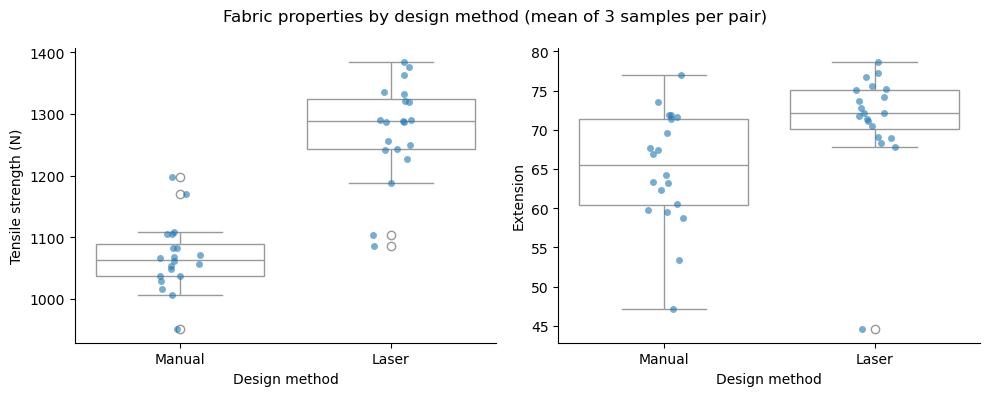

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, var, label in zip(axes, ['strength', 'extension'], ['Tensile strength (N)', 'Extension']):
    sns.boxplot(data=df_jeans_avg, x='method', y=var, color='white', ax=ax)
    sns.stripplot(data=df_jeans_avg, x='method', y=var, alpha=0.6, ax=ax)
    ax.set_xlabel('Design method')
    ax.set_ylabel(label)
fig.suptitle('Fabric properties by design method (mean of 3 samples per pair)')
sns.despine()
plt.tight_layout()


## Dataset 4: "Southern Crime"

Description:

This dataset contains a variety of data on crime rates in different states in the United States. 

| CrimeRate          | Crime rate (number of offences per million population)             | Continuous |
|--------------------|--------------------------------------------------------------------|------------|
| Youth              | Young males (number of males aged 18-24 per 1000)                  | Discrete   |
| Southern           | Southern state 1 = yes, 0 = no                                     | Binary     |
| Education          | Education time (average years of schooling of people aged 25+)    | Discrete   |
| ExpenditureYear0   | Expenditure (per capita expenditure on police)  skewed             | Continuous |
| LabourForce        | Youth labour force (males employed 18-24 per 1000)                 | Discrete   |
| Males              | Males (per 1000 females)                                           | Discrete   |
| MoreMales          | More males identified per 1000 females 1 = yes, 0 = no             | Binary     |
| StateSize          | State size (in hundred thousands)                                  | Discrete   |
| YouthUnemployment  | Youth Unemployment (unemployed males aged 18-24 per 1000) skewed  | Discrete   |
| MatureUnemployment | Mature Unemployment (unemployed males aged 35-39 per 1000)        | Discrete   |
| HighYouthUnemploy  | High Youth Unemployment 1 = yes, 0 = no (high if Youth >3*Mature ) | Binary     |
| Wage               | Wage (median weekly wage)                                          | Continuous |
| BelowWage          | Below Wage (number of families below half wage per 1000)           | Discrete   |

The dataset also contains a second set of columns ending in `10` (e.g. `CrimeRate10`). These are the same measures taken ten years later. For this assignment, use `CrimeRate`.


Assignment:
Examine whether there is a significant difference in crime rates between Southern and non-Southern states. Calculate an appropriate test statistic, and make a figure illustrating the comparison. Write a sentence reporting your results in the same way they are reported in the book (APA format): 

> With a mean grade of 72.3, the psychology students scored slightly higher than the average grade of 67.5 (𝑡(19)=2.25, 𝑝<.05)

Source:

MASH (Mathematics and Statistics Help), University of Sheffield.

In [ ]:
df_crime = pd.read_csv('https://raw.githubusercontent.com/ethanweed/datasets-for-teaching/main/sheffield_MASH/crime.csv')
df_crime.head()

## Dataset 5: "Weight Gain"

Description:

This data set, "Weight Gain", provides weights of 16 participants before and after an eight-week period of excessive calorie intake (Moore et al., 2012, p. 425).

Variables:

Weight Before: Weight in pounds (lb) measured before eight weeks of excessive calorie intake.  
Weight After: Weight in pounds (lb) measured after eight weeks of excessive calorie intake.  
Difference: Weight After - Weight Before.  

Assignment:

Test the hypothesis that consuming 1000 excess calories per day over 8 weeks results in 16 pounds (approximately 7.2 kilograms) weight increase. Calculate an appropriate test statistic, and make a figure illustrating the comparison. Write a sentence reporting your results in the same way they are reported in the book (APA format): 

> With a mean grade of 72.3, the psychology students scored slightly higher than the average grade of 67.5 (𝑡(19)=2.25, 𝑝<.05) 

References:

Moore, D. S., McCabe, G. P., and Craig, B. A. (2012). Introduction to the Practice of Statistics (7th ed.). New York: Freeman.

Levine, J. A., Eberhardt, N. L., and Jensen, M. D. (1999). Role of nonexercise activity thermogenesis in resistance to fat gain in humans. Science, 283, 212–214.

In [ ]:
df_weight = pd.read_csv("https://raw.githubusercontent.com/ethanweed/datasets-for-teaching/main/JASP_data_library/2.%20T-Tests/Weight%20Gain.csv")
df_weight.head()